# LeetCode #142: Linked List Cycle II

https://leetcode.com/problems/linked-list-cycle-ii/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| HashSet | O(n) | O(n) |
| Floyd's + Math ★ | O(n) | O(1) |

## Understanding the Methods
### Brute Force (HashSet)
Traverse the list, storing each visited node. The first node visited twice is the cycle entry point. O(n) time and space.

### Optimal: Floyd's + Math ★
Phase 1: Use slow/fast pointers to detect a meeting point inside the cycle.
Phase 2: Move one pointer to head, keep the other at the meeting point. Both move one step at a time. They meet at the cycle entry node.
Mathematical proof: if the head-to-entry distance is F and the entry-to-meeting distance is a, then F = C - a (C = cycle length), so starting fresh from head meets the other pointer exactly at the entry.

## Solutions
### C#

In [ ]:
// Floyd's Two-Phase O(n) time, O(1) space
public class Solution {
    public ListNode DetectCycle(ListNode head) {
        var slow = head;
        var fast = head;
        while (fast != null && fast.next != null) {
            slow = slow.next;
            fast = fast.next.next;
            if (slow == fast) {
                slow = head;
                while (slow != fast) { slow = slow.next; fast = fast.next; }
                return slow;
            }
        }
        return null;
    }
}

### Python

In [ ]:
# Floyd's Two-Phase O(n) time, O(1) space
class Solution:
    def detectCycle(self, head: 'Optional[ListNode]') -> 'Optional[ListNode]':
        slow = fast = head
        while fast and fast.next:
            slow = slow.next
            fast = fast.next.next
            if slow is fast:
                slow = head
                while slow is not fast:
                    slow = slow.next
                    fast = fast.next
                return slow
        return None

### Go

In [ ]:
// Floyd's Two-Phase O(n) time, O(1) space
func detectCycle(head *ListNode) *ListNode {
    slow, fast := head, head
    for fast != nil && fast.Next != nil {
        slow = slow.Next
        fast = fast.Next.Next
        if slow == fast {
            slow = head
            for slow != fast { slow = slow.Next; fast = fast.Next }
            return slow
        }
    }
    return nil
}

### Rust

In [ ]:
// Floyd's Two-Phase with raw pointers
pub fn detect_cycle(head: *mut ListNode) -> *mut ListNode {
    unsafe {
        let (mut slow, mut fast) = (head, head);
        loop {
            if fast.is_null() { return std::ptr::null_mut(); }
            let fast_next = (*fast).next as *mut ListNode;
            if fast_next.is_null() { return std::ptr::null_mut(); }
            slow = (*slow).next as *mut ListNode;
            fast = (*fast_next).next as *mut ListNode;
            if slow == fast {
                slow = head;
                while slow != fast {
                    slow = (*slow).next as *mut ListNode;
                    fast = (*fast).next as *mut ListNode;
                }
                return slow;
            }
        }
    }
}

## Example Scenarios

### 1. Common Case — Cycle in the Middle
**Input:** `head=[3,2,0,-4]`, `pos=1`

The tail $-4$ links back to the node at index $1$ (value $2$). Slow and fast meet inside the loop; resetting slow to head and advancing both one step at a time, they re-meet exactly at the entry node (value $2$).

### 2. Slightly Complex — Two-Node Cycle
**Input:** `head=[1,2]`, `pos=0`

The tail $2$ points back to the head $1$. Floyd's pointers meet, then the reset phase returns the node at index $0$ (value $1$) as the cycle start.

### 3. Edge Case: Time Factor — No Cycle
**Input:** `head=[1]`, `pos=-1`

A single node pointing to `null`. Fast reaches the end ($O(n)$ with no revisit), slow and fast never meet, so the answer is `null`.

### 4. Edge Case: Space Factor — Long Tail, Deep Cycle
**Input:** `head=[1,2,3,4,5]`, `pos=2`

Tail $5$ loops back to index $2$ (value $3$). Despite the long non-cyclic prefix, Floyd uses only $O(1)$ extra space to locate the entry at value $3$.

### 5. Almost-Impossible but Plausible — Self Loop
**Input:** `head=[1]`, `pos=0`

The lone node points to itself. Slow and fast coincide immediately; the cycle start is the node itself (value $1$).


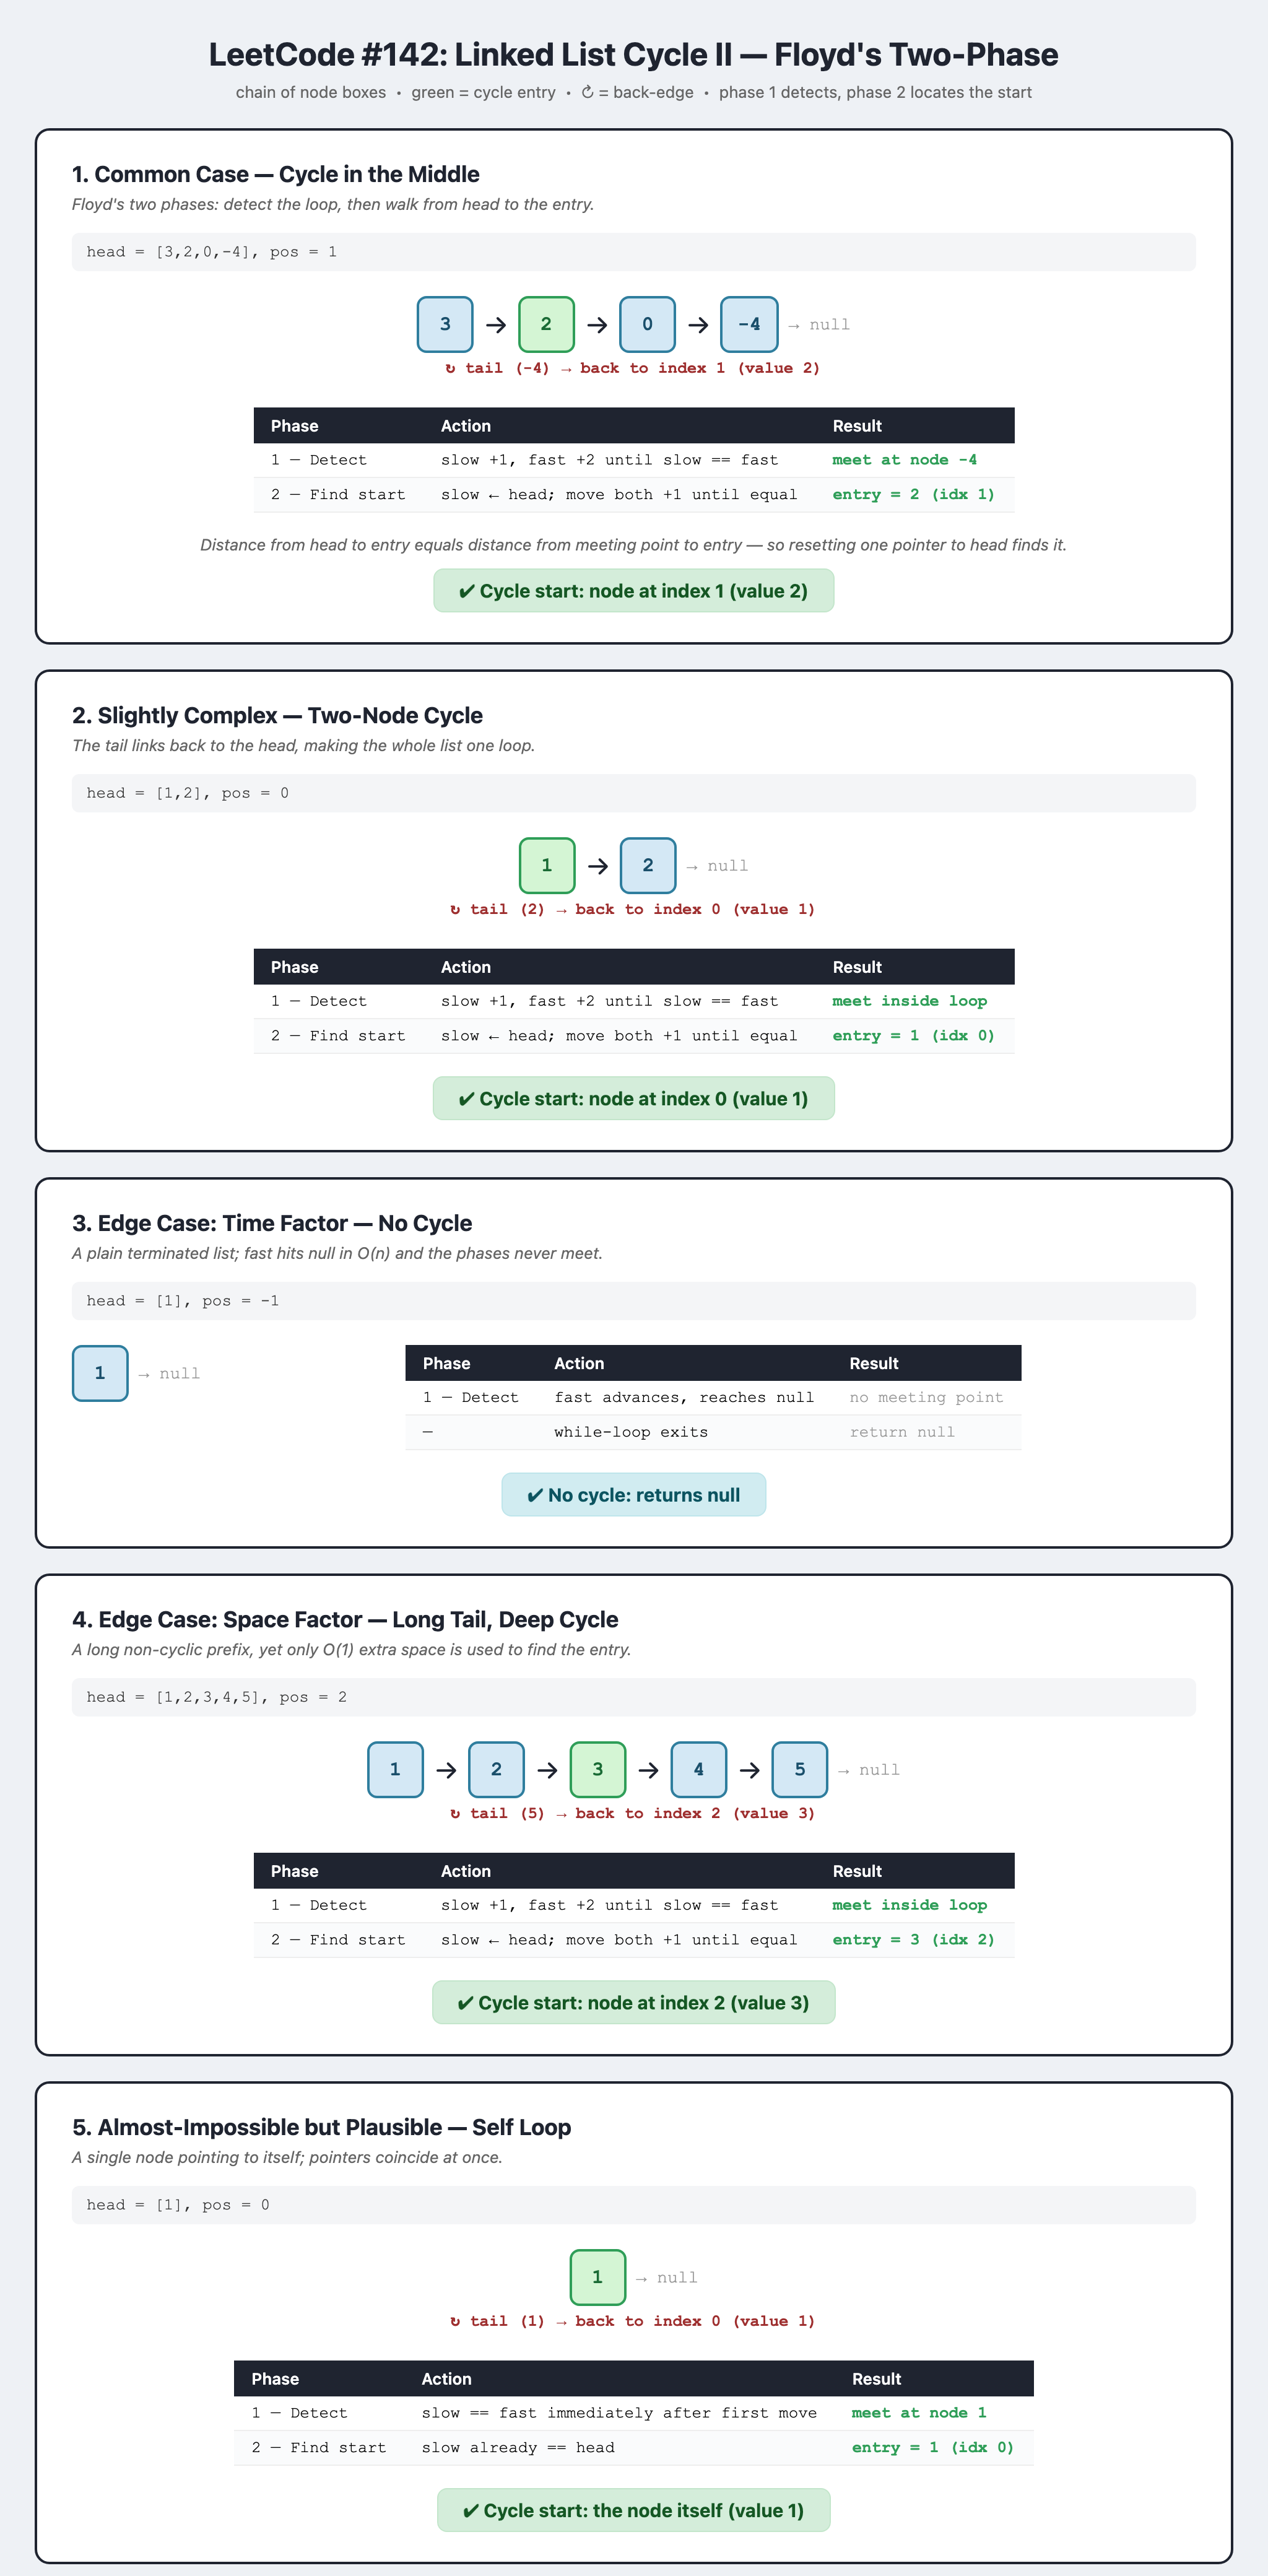